# Notebook 3: Signal-quality model, "can I trust this heart-rate reading?"

**The idea.** Our heart-rate estimator (method B + narrow search, frozen from notebook 2)
is right in some windows and badly wrong in others, and it can't tell which.
Here we train a small model that looks only at what a device can see
(the signal's shape and the wrist motion, **never the ECG**) and predicts
**"is this reading within `GOOD_BPM` of the truth?"**

**The payoff chart.** If the device only shows a number when the model says
"trustworthy", how much does the error drop, and how often does it still show a number?
That is called a **risk-coverage curve**.

**Honest evaluation.** Leave-one-subject-out: for each person, the model is trained on
the other 14 and tested on them. Nothing from the tested person is used for training.

In [1]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count() or 4))  # silences a harmless Windows warning
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.inspection import permutation_importance

In [2]:
DATA_ROOT = r"C:\Users\diya0\Downloads\ppg+dalia\data\PPG_FieldStudy"      # folder where you unzipped PPG-DaLiA (searched recursively)
RESULTS_DIR = "../results"
MAKE_FAKE = False                # True = dry run on synthetic data (writes to ../dryrun, never to ../results)
if MAKE_FAKE:
    DATA_ROOT, RESULTS_DIR = "../dryrun/fake_dalia", "../dryrun/results"

FS_PPG, FS_ACC, FS_ACT = 64, 32, 4
WIN_S, SHIFT_S = 8, 2
F_LO, F_HI = 0.7, 3.5
N_FFT = 4096
ALPHA = 0.9
RESET_RATIO, RESET_AFTER = 0.3, 5
SEARCH_BPM = 10            # frozen from notebook 2 (chosen on S1-S8)
GOOD_BPM = 10              # a reading counts as "good" if within 10 bpm of the ECG heart rate
SECOND_PEAK_EXCL_BPM = 8
TEST_MIN_SUBJECT = 9       # S9+ were not used to pick SEARCH_BPM, so we also report them separately

ACTIVITY_NAMES = {0: "transient", 1: "sitting", 2: "stairs", 3: "table soccer",
                  4: "cycling", 5: "driving", 6: "lunch break", 7: "walking", 8: "working"}
os.makedirs(RESULTS_DIR, exist_ok=True)

## Optional dry run with fake data

In [3]:
def make_fake_dataset(root, n_subjects=4, minutes=8, seed=0):
    rng = np.random.default_rng(seed)
    for sid in range(1, n_subjects + 1):
        secs = minutes * 60
        t = np.arange(secs * FS_PPG) / FS_PPG
        hr_t = 105 + 40 * np.sin(2 * np.pi * t / 240 + sid) + 5 * np.sin(2 * np.pi * t / 37)
        phase = 2 * np.pi * np.cumsum(hr_t / 60) / FS_PPG
        act_t = np.repeat([1, 7, 4], secs // 3 * FS_ACT)[: secs * FS_ACT]
        act_t = np.pad(act_t, (0, secs * FS_ACT - len(act_t)), constant_values=4)
        moving = np.repeat(act_t != 1, FS_PPG // FS_ACT)[: len(t)]
        step_hz = 1.6 + 0.4 * np.sin(2 * np.pi * t / 90)
        step_phase = 2 * np.pi * np.cumsum(step_hz) / FS_PPG
        ppg = np.sin(phase) + 0.3 * np.sin(2 * phase)
        ppg = ppg + moving * 1.2 * np.sin(step_phase) + 0.2 * rng.standard_normal(len(t))
        acc = np.stack([moving * 30 * np.sin(step_phase + k) for k in range(3)], axis=1)
        acc = acc[:: FS_PPG // FS_ACC] + 1.5 * rng.standard_normal((secs * FS_ACC, 3))
        n_win = (secs - WIN_S) // SHIFT_S + 1
        label = np.array([hr_t[i * SHIFT_S * FS_PPG: (i * SHIFT_S + WIN_S) * FS_PPG].mean()
                          for i in range(n_win)])
        d = {"signal": {"wrist": {"BVP": ppg[:, None], "ACC": acc}},
             "label": label, "activity": act_t[:, None], "subject": f"S{sid}"}
        os.makedirs(os.path.join(root, f"S{sid}"), exist_ok=True)
        with open(os.path.join(root, f"S{sid}", f"S{sid}.pkl"), "wb") as f:
            pickle.dump(d, f, protocol=2)

if MAKE_FAKE:
    make_fake_dataset(DATA_ROOT)
    GOOD_BPM = 2      # fake data is too easy; use a strict rule so both classes exist
    print("DRY RUN with fake data: numbers are meaningless.")

## 1. Load, filter, window, spectra (same as notebook 2; cached so reruns are fast)
If you change the data or the settings above, delete the cache file in `results/`.

In [4]:
def index_pkls(root):
    found = {}
    for dirpath, _, files in os.walk(root):
        for fn in files:
            if fn.startswith("S") and fn.endswith(".pkl"):
                try:
                    found[int(fn[1:-4])] = os.path.join(dirpath, fn)
                except ValueError:
                    pass
    return found

PKL = index_pkls(DATA_ROOT)
SUBJECTS = sorted(PKL)
print("Subjects found:", SUBJECTS)
assert PKL, f"No S*.pkl files under '{DATA_ROOT}'. Check DATA_ROOT."

def load_subject(sid):
    with open(PKL[sid], "rb") as f:
        d = pickle.load(f, encoding="latin1")
    bvp = np.asarray(d["signal"]["wrist"]["BVP"], dtype=float).ravel()
    acc = np.asarray(d["signal"]["wrist"]["ACC"], dtype=float)
    hr = np.asarray(d["label"], dtype=float).ravel()
    act = np.asarray(d["activity"]).ravel().astype(int)
    return bvp, acc, hr, act

def bandpass(x, fs, lo=0.5, hi=4.0, order=4):
    sos = butter(order, [lo, hi], btype="band", fs=fs, output="sos")
    return sosfiltfilt(sos, x)

def make_windows(bvp, acc, hr, act):
    wp, sp = WIN_S * FS_PPG, SHIFT_S * FS_PPG
    wa, sa = WIN_S * FS_ACC, SHIFT_S * FS_ACC
    n = min(len(hr), (len(bvp) - wp) // sp + 1, (len(acc) - wa) // sa + 1)
    ppg_w = np.stack([bvp[i * sp: i * sp + wp] for i in range(n)])
    acc_w = np.stack([acc[i * sa: i * sa + wa] for i in range(n)])
    act_w = np.array([np.bincount(act[i * SHIFT_S * FS_ACT:(i * SHIFT_S + WIN_S) * FS_ACT]).argmax()
                      for i in range(n)])
    return ppg_w, acc_w, hr[:n], act_w

FREQS = np.fft.rfftfreq(N_FFT, 1 / FS_PPG)
BAND = (FREQS >= F_LO) & (FREQS <= F_HI)
FB = FREQS[BAND]
BPM = 60 * FB

def spectrum(x, fs, n_fft):
    x = (x - x.mean()) * np.hanning(len(x))
    return np.fft.rfftfreq(n_fft, 1 / fs), np.abs(np.fft.rfft(x, n=n_fft))

def acc_spectrum_on_grid(acc_win):
    n_fft = N_FFT * FS_ACC // FS_PPG
    total = 0
    for ax in range(3):
        fa, sa = spectrum(acc_win[:, ax], FS_ACC, n_fft)
        total = total + np.interp(FB, fa, sa)
    return total / (total.max() + 1e-12)

CACHE = os.path.join(RESULTS_DIR, f"spec_cache_{os.path.basename(os.path.normpath(DATA_ROOT))}.pkl")
SPEC = None
if os.path.exists(CACHE):
    with open(CACHE, "rb") as f:
        SPEC = pickle.load(f)
    if sorted(SPEC) == SUBJECTS:
        print("loaded cached spectra from", CACHE)
    else:
        print("cache does not match the subjects found; recomputing")
        SPEC = None
if SPEC is None:
    SPEC = {}
    for sid in SUBJECTS:
        print(f"spectra for S{sid} ...", end=" ")
        bvp, acc, hr, act = load_subject(sid)
        bvp_f = bandpass(bvp, FS_PPG)
        acc_f = np.column_stack([bandpass(acc[:, k], FS_ACC) for k in range(3)])
        ppg_w, acc_w, hr_w, act_w = make_windows(bvp_f, acc_f, hr, act)
        energy = (np.linalg.norm(acc_w, axis=2) ** 2).mean(axis=1)
        lo, hi = np.percentile(energy, [10, 90])
        motion = np.clip((energy - lo) / (hi - lo + 1e-12), 0, 1)
        SPEC[sid] = dict(
            ppg=np.stack([spectrum(w, FS_PPG, N_FFT)[1][BAND] for w in ppg_w]).astype(np.float32),
            acc=np.stack([acc_spectrum_on_grid(w) for w in acc_w]).astype(np.float32),
            motion=motion, energy=energy, hr=hr_w,
            act=np.array([ACTIVITY_NAMES.get(x, str(x)) for x in act_w]))
        print("done")
    with open(CACHE, "wb") as f:
        pickle.dump(SPEC, f)

Subjects found: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
loaded cached spectra from ../results\spec_cache_PPG_FieldStudy.pkl


## 2. The frozen estimator, now also recording "quality features"
For every window we save simple facts about the signal. **None of them use the ECG.**

| Feature | Plain meaning |
|---|---|
| `peak_dominance` | How much of the PPG spectrum sits in the chosen peak (a clean pulse has one clear peak) |
| `peak_vs_median` | Peak height compared with typical background level |
| `second_peak_ratio` | Height of the best *other* peak (>8 bpm away) vs the chosen one. High = ambiguous |
| `acc_at_peak` | How loud the accelerometer is at the chosen frequency. High = could be motion, not heartbeat |
| `motion` | How much the wrist is moving (0 = still, 1 = very active; scaled per person) |
| `log_acc_energy` | Raw wrist-movement energy (log) |
| `jump_bpm` | Change from the previous estimate |
| `recent_std` | Wobble of the last 5 estimates |
| `est_bpm` | The estimate itself |
| `local_ratio` | Strength of the chosen peak vs the strongest peak overall (tracker's own confidence) |
| `weak_count` | Consecutive windows where the tracker was unsure |

In [5]:
FEATURES = ["peak_dominance", "peak_vs_median", "second_peak_ratio", "acc_at_peak",
            "motion", "log_acc_energy", "jump_bpm", "recent_std", "est_bpm",
            "local_ratio", "weak_count"]

def run_estimator(S):
    ppg, accs, motion, energy = S["ppg"], S["acc"], S["motion"], S["energy"]
    n = len(ppg)
    est = np.zeros(n)
    X = np.zeros((n, len(FEATURES)))
    prev, weak = None, 0
    for i in range(n):
        raw = ppg[i]
        s = raw * (1 - ALPHA * motion[i] * accs[i])
        k = int(np.argmax(s))
        local_ratio = 1.0
        if prev is not None:
            idx = np.where(np.abs(BPM - prev) <= SEARCH_BPM)[0]
            local = idx[int(np.argmax(s[idx]))]
            local_ratio = s[local] / (s[k] + 1e-12)
            if s[local] < RESET_RATIO * s[k]:
                weak += 1
            else:
                weak = 0
            if weak < RESET_AFTER:
                k = int(local)
            else:
                weak = 0
        est[i] = BPM[k]
        far = np.abs(BPM - est[i]) > SECOND_PEAK_EXCL_BPM
        second = raw[far].max() if far.any() else 0.0
        recent = est[max(0, i - 4): i + 1]
        X[i] = [raw[k] / (raw.sum() + 1e-12),
                raw[k] / (np.median(raw) + 1e-12),
                second / (raw[k] + 1e-12),
                accs[i][k],
                motion[i],
                np.log(energy[i] + 1e-9),
                0.0 if prev is None else abs(est[i] - prev),
                recent.std(),
                est[i],
                local_ratio,
                weak]
        prev = est[i]
    return est, X

frames = []
for sid in SUBJECTS:
    S = SPEC[sid]
    est, X = run_estimator(S)
    d = pd.DataFrame(X, columns=FEATURES)
    d["subject"], d["window"] = sid, np.arange(len(est))
    d["activity"], d["hr_true"], d["est"] = S["act"], S["hr"], est
    frames.append(d)
data = pd.concat(frames, ignore_index=True)
data["err"] = (data["est"] - data["hr_true"]).abs()
data["good"] = (data["err"] <= GOOD_BPM).astype(int)

print(f"{len(data)} windows | overall MAE {data.err.mean():.2f} bpm | "
      f"{100 * data.good.mean():.1f}% of windows are 'good' (within {GOOD_BPM} bpm)")
t = data[data.subject >= TEST_MIN_SUBJECT]
if len(t):
    print(f"Sanity check, S{TEST_MIN_SUBJECT}+ MAE = {t.err.mean():.2f} "
          f"(notebook 2's 'B + narrow search' gave 13.44, which should match)")

64697 windows | overall MAE 15.04 bpm | 63.2% of windows are 'good' (within 10 bpm)
Sanity check, S9+ MAE = 13.44 (notebook 2's 'B + narrow search' gave 13.44, which should match)


## 3. Train and test the quality model, leave-one-subject-out
We use gradient boosting (a tree-based model, no GPU needed).
The output `p_good` is the model's probability that the reading is within `GOOD_BPM`.

In [6]:
def make_model():
    return HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_depth=4,
                                          min_samples_leaf=50, random_state=0)

data["p_good"] = np.nan
importances = []
for sid in SUBJECTS:
    tr, te = data.subject != sid, data.subject == sid
    ytr = data.loc[tr, "good"]
    if ytr.nunique() < 2:
        data.loc[te, "p_good"] = float(ytr.iloc[0])
        continue
    model = make_model().fit(data.loc[tr, FEATURES], ytr)
    data.loc[te, "p_good"] = model.predict_proba(data.loc[te, FEATURES])[:, 1]
    yte = data.loc[te, "good"]
    if yte.nunique() == 2:
        r = permutation_importance(model, data.loc[te, FEATURES], yte, scoring="roc_auc",
                                   n_repeats=3, random_state=0)
        importances.append(r.importances_mean)
    print(f"held-out S{sid} done")

# simple comparison scores (higher = more trusted)
data["s_model"] = data["p_good"]
data["s_motion_only"] = -data["motion"]
data["s_peak_only"] = data["peak_dominance"]

def safe_auc(y, s):
    return roc_auc_score(y, s) if y.nunique() == 2 else np.nan

auc = pd.DataFrame({
    name: {"AUC pooled": safe_auc(data.good, data[col]),
           "AUC median per person": np.nanmedian([safe_auc(g.good, g[col]) for _, g in data.groupby("subject")])}
    for name, col in [("model (all features)", "s_model"), ("motion only", "s_motion_only"),
                      ("peak dominance only", "s_peak_only")]}).T.round(3)
print("\nHow well does each score separate good from bad readings? (0.5 = coin flip, 1 = perfect)")
print(auc.to_string())
auc.to_csv(os.path.join(RESULTS_DIR, "03_auc.csv"))

C:\Users\diya0\AppData\Roaming\Python\Python312\site-packages\joblib\externals\loky\backend\context.py:110: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\diya0\AppData\Roaming\Python\Python312\site-packages\joblib\externals\loky\backend\context.py", line 199, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Program Files\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Program Files\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Program Files\Python312\Lib\subprocess.py", line 1538, in _execute_ch

held-out S1 done
held-out S2 done
held-out S3 done
held-out S4 done
held-out S5 done
held-out S6 done
held-out S7 done
held-out S8 done
held-out S9 done
held-out S10 done
held-out S11 done
held-out S12 done
held-out S13 done
held-out S14 done
held-out S15 done

How well does each score separate good from bad readings? (0.5 = coin flip, 1 = perfect)
                      AUC pooled  AUC median per person
model (all features)       0.954                  0.969
motion only                0.708                  0.723
peak dominance only        0.816                  0.806


## 4. The payoff: error vs how often the device shows a number
Sort windows from most to least trusted. If we only report the top 70%, what is the error?

In [7]:
def risk_coverage(d, col):
    o = d.sort_values(col, ascending=False)
    e = o["err"].to_numpy()
    k = np.arange(1, len(e) + 1)
    return k / len(e), np.cumsum(e) / k, np.cumsum(e > 20) / k * 100

def coverage_table(d):
    rows = []
    for name, col in [("model", "s_model"), ("motion only", "s_motion_only"),
                      ("peak dominance only", "s_peak_only")]:
        cov, mae, bad = risk_coverage(d, col)
        for c in [1.0, 0.9, 0.8, 0.7, 0.6, 0.5]:
            j = max(int(round(c * len(cov))) - 1, 0)
            rows.append({"score": name, "report HR in (% of windows)": int(c * 100),
                         "MAE (bpm)": round(mae[j], 2), "% err>20bpm": round(bad[j], 1)})
    return (pd.DataFrame(rows).pivot(index="report HR in (% of windows)", columns="score",
                                     values=["MAE (bpm)", "% err>20bpm"]).sort_index(ascending=False))

print("ALL subjects (leave-one-subject-out):")
tab_all = coverage_table(data)
print(tab_all.to_string())
tab_all.to_csv(os.path.join(RESULTS_DIR, "03_risk_coverage_all.csv"))

test_df = data[data.subject >= TEST_MIN_SUBJECT]
if len(test_df):
    print(f"\nOnly S{TEST_MIN_SUBJECT}+ (not used to pick the estimator's settings):")
    tab_test = coverage_table(test_df)
    print(tab_test.to_string())
    tab_test.to_csv(os.path.join(RESULTS_DIR, "03_risk_coverage_test.csv"))

ALL subjects (leave-one-subject-out):
                            MAE (bpm)                                 % err>20bpm                                
score                           model motion only peak dominance only       model motion only peak dominance only
report HR in (% of windows)                                                                                      
100                             15.04       15.04               15.04        26.9        26.9                26.9
90                              11.41       13.83               13.35        19.4        24.6                23.2
80                               8.06       12.60               11.97        12.1        22.2                20.3
70                               5.50       11.43               10.50         6.4        20.0                17.3
60                               3.76       10.03                8.90         2.9        17.3                14.0
50                               2.58        8.74 

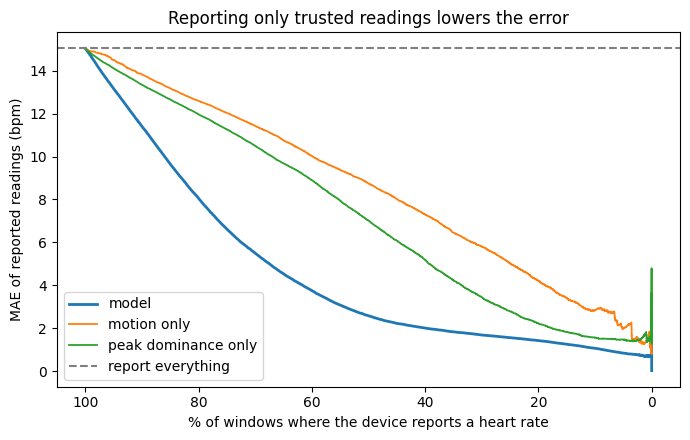

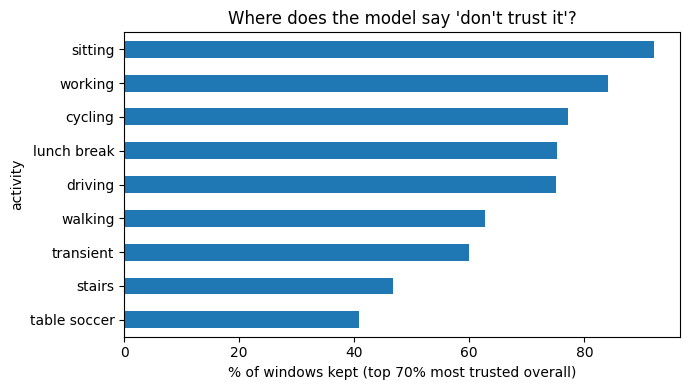

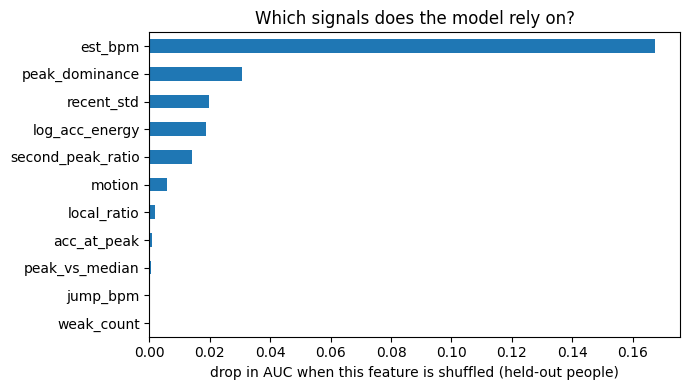

In [8]:
plt.figure(figsize=(7, 4.5))
for name, col in [("model", "s_model"), ("motion only", "s_motion_only"),
                  ("peak dominance only", "s_peak_only")]:
    cov, mae, _ = risk_coverage(data, col)
    plt.plot(cov * 100, mae, label=name, lw=2 if name == "model" else 1.3)
plt.axhline(data.err.mean(), color="gray", ls="--", label="report everything")
plt.xlabel("% of windows where the device reports a heart rate")
plt.ylabel("MAE of reported readings (bpm)")
plt.title("Reporting only trusted readings lowers the error")
plt.gca().invert_xaxis(); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "03_chart_risk_coverage.png"), dpi=150)
plt.show()

# which activities does the model refuse to report on, if we keep the top 70%?
cut = data["s_model"].quantile(0.30)
kept = (data["s_model"] >= cut).groupby(data["activity"]).mean() * 100
ax = kept.sort_values().plot.barh(figsize=(7, 4))
ax.set_xlabel("% of windows kept (top 70% most trusted overall)")
ax.set_title("Where does the model say 'don't trust it'?")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "03_chart_kept_by_activity.png"), dpi=150)
plt.show()

if importances:
    imp = pd.Series(np.mean(importances, axis=0), index=FEATURES).sort_values()
    ax = imp.plot.barh(figsize=(7, 4))
    ax.set_xlabel("drop in AUC when this feature is shuffled (held-out people)")
    ax.set_title("Which signals does the model rely on?")
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, "03_chart_feature_importance.png"), dpi=150)
    plt.show()

data.to_csv(os.path.join(RESULTS_DIR, "03_window_predictions.csv"), index=False)

## 5. Sanity check: is the model judging the *signal*, or just guessing from the heart-rate value?
The importance chart showed `est_bpm` (the estimate itself) matters far more than anything else.
That could be legitimate (the estimator fails at typical wrong values, such as stuck near
42 bpm), but it means part of the model's skill is a "plausible heart rate" prior, not a
measurement of signal quality. We test this by retraining without it.

* **no est_bpm:** all features except the heart-rate value
* **signal-only:** only features that describe the PPG and accelerometer signals
  (no heart-rate value, and nothing derived from the tracker's past estimates)

                      AUC pooled  MAE @70% (all)  MAE @50% (all)  MAE @70% (S9+)  MAE @50% (S9+)
variant                                                                                         
full model                 0.954            5.50            2.58            4.46            2.17
no est_bpm                 0.873            9.06            4.89            7.81            4.03
signal-only features       0.851            9.27            5.24            7.94            4.30
peak dominance only        0.816           10.50            7.02            9.18            6.24
motion only                0.708           11.43            8.74            9.87            7.42


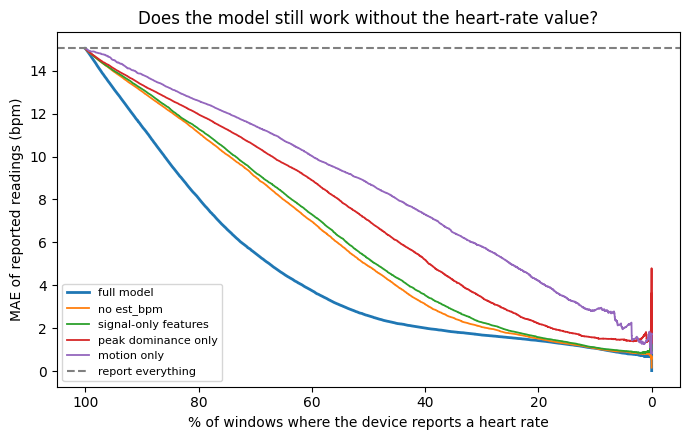

In [9]:
def loso_scores(features, col):
    data[col] = np.nan
    for sid in SUBJECTS:
        tr, te = data.subject != sid, data.subject == sid
        ytr = data.loc[tr, "good"]
        if ytr.nunique() < 2:
            data.loc[te, col] = float(ytr.iloc[0])
            continue
        m = make_model().fit(data.loc[tr, features], ytr)
        data.loc[te, col] = m.predict_proba(data.loc[te, features])[:, 1]

NO_EST = [f for f in FEATURES if f != "est_bpm"]
SIGNAL_ONLY = ["peak_dominance", "peak_vs_median", "second_peak_ratio",
               "acc_at_peak", "motion", "log_acc_energy"]
loso_scores(NO_EST, "s_model_no_est")
loso_scores(SIGNAL_ONLY, "s_model_signal")
test_df = data[data.subject >= TEST_MIN_SUBJECT]     # re-take, so it includes the new columns

variants = {"full model": "s_model", "no est_bpm": "s_model_no_est",
            "signal-only features": "s_model_signal",
            "peak dominance only": "s_peak_only", "motion only": "s_motion_only"}
rows = []
for name, col in variants.items():
    row = {"variant": name, "AUC pooled": round(safe_auc(data.good, data[col]), 3)}
    for label, d in [("all", data), (f"S{TEST_MIN_SUBJECT}+", test_df)]:
        if len(d) == 0:
            continue
        cov, mae, bad = risk_coverage(d, col)
        for c in (0.7, 0.5):
            j = max(int(round(c * len(cov))) - 1, 0)
            row[f"MAE @{int(c * 100)}% ({label})"] = round(mae[j], 2)
    rows.append(row)
ablate = pd.DataFrame(rows).set_index("variant")
print(ablate.to_string())
ablate.to_csv(os.path.join(RESULTS_DIR, "03_ablation_features.csv"))

plt.figure(figsize=(7, 4.5))
for name, col in variants.items():
    cov, mae, _ = risk_coverage(data, col)
    plt.plot(cov * 100, mae, label=name, lw=2 if name == "full model" else 1.3)
plt.axhline(data.err.mean(), color="gray", ls="--", label="report everything")
plt.xlabel("% of windows where the device reports a heart rate")
plt.ylabel("MAE of reported readings (bpm)")
plt.title("Does the model still work without the heart-rate value?")
plt.gca().invert_xaxis(); plt.legend(fontsize=8); plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "03_chart_ablation.png"), dpi=150)
plt.show()
data.to_csv(os.path.join(RESULTS_DIR, "03_window_predictions.csv"), index=False)   # read by notebook 4